# RFM Analizi və Müştəri Seqmentasiyası
### E-commerce Müştəri Davranışı Dataseti üzərində

**Layihənin məqsədi:** Müştəriləri alış-veriş davranışlarına görə (Recency, Frequency, Monetary) seqmentlərə bölmək və hər seqment üçün biznes tövsiyələri hazırlamaq.

**Dataset:** 17,049 sifariş, 5,000 unikal müştəri (2023-01-01 — 2024-03-25 aralığı)

---


## 1. Kitabxanaların import edilməsi və datanın yüklənməsi

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

df = pd.read_csv('ecommerce_customer_behavior_dataset_v2.csv')
df['Date'] = pd.to_datetime(df['Date'])

print(f"Sətir sayı: {df.shape[0]}")
print(f"Sütun sayı: {df.shape[1]}")
df.head()


Sətir sayı: 17049
Sütun sayı: 18


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


## 2. İlkin Data Araşdırması (EDA)

Analizə başlamazdan əvvəl datanın keyfiyyətini və strukturunu yoxlayırıq: eksik dəyərlər, dublikatlar, tarix aralığı və əsas statistikalar.

In [2]:
# Eksik dəyərlər
print("Eksik dəyərlər:")
print(df.isnull().sum().sum(), "ədəd eksik dəyər")

# Dublikat sifarişlər
print(f"\nDublikat sətirlər: {df.duplicated().sum()}")

# Tarix aralığı
print(f"\nTarix aralığı: {df['Date'].min().date()} - {df['Date'].max().date()}")

# Unikal müştəri sayı
print(f"Unikal müştəri sayı: {df['Customer_ID'].nunique()}")
print(f"Ümumi sifariş sayı: {df['Order_ID'].nunique()}")


Eksik dəyərlər:
0 ədəd eksik dəyər

Dublikat sətirlər: 0

Tarix aralığı: 2023-01-01 - 2024-03-25
Unikal müştəri sayı: 5000
Ümumi sifariş sayı: 17049


In [3]:
# Əsas statistikalar
df[['Age', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount']].describe()


,Age,Unit_Price,Quantity,Discount_Amount,Total_Amount
count,17049.000000,17049.000000,17049.000000,17049.000000,17049.000000
mean,34.945745,447.901689,3.011379,69.788135,1277.438711
std,11.046855,722.319705,1.417027,240.704662,2358.436375
min,18.000000,5.050000,1.000000,0.000000,6.210000
25%,26.000000,73.260000,2.000000,0.000000,172.970000
50%,35.000000,174.680000,3.000000,0.000000,455.850000
75%,42.000000,494.570000,4.000000,32.710000,1267.750000
max,75.000000,7900.010000,5.000000,6538.290000,37852.050000


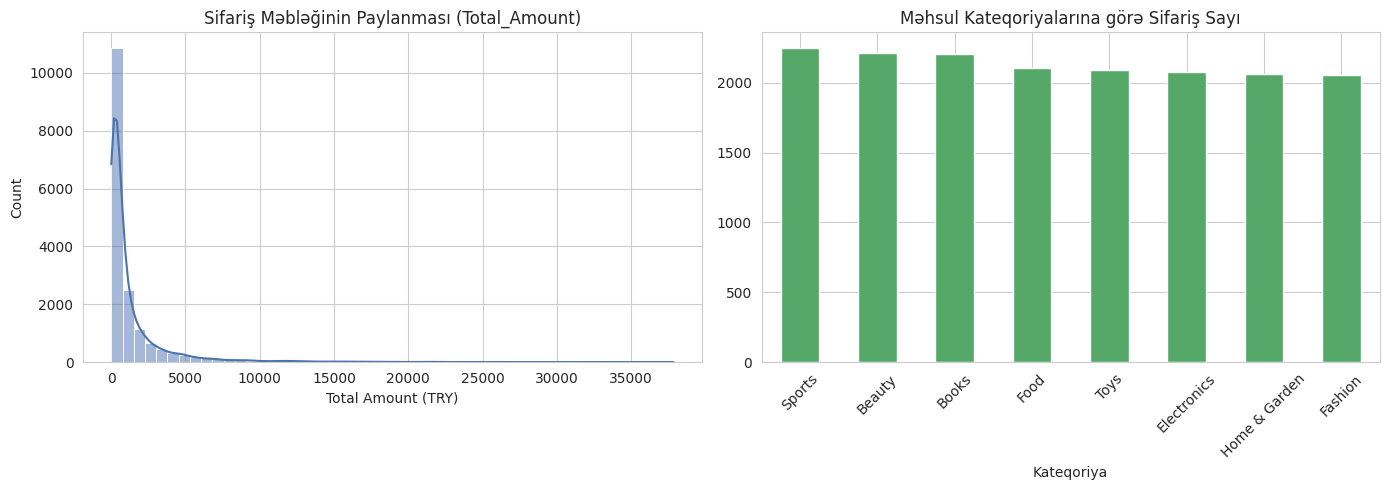

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Total_Amount'], bins=50, kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('Sifariş Məbləğinin Paylanması (Total_Amount)')
axes[0].set_xlabel('Total Amount (TRY)')

df['Product_Category'].value_counts().plot(kind='bar', ax=axes[1], color='#55A868')
axes[1].set_title('Məhsul Kateqoriyalarına görə Sifariş Sayı')
axes[1].set_xlabel('Kateqoriya')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 3. RFM Metriklərinin Hesablanması

RFM analizi üç göstəriciyə əsaslanır:

- **Recency (R)** — Müştərinin son alış-verişindən neçə gün keçib? (nə qədər az, o qədər yaxşı)
- **Frequency (F)** — Müştəri neçə dəfə sifariş verib? (nə qədər çox, o qədər yaxşı)
- **Monetary (M)** — Müştərinin ümumi xərclədiyi məbləğ nə qədərdir? (nə qədər çox, o qədər yaxşı)

Analiz tarixi kimi datasetdəki son sifariş tarixindən 1 gün sonrasını götürürük — bu, "bugün" kimi qəbul edilir.

In [5]:
analysis_date = df['Date'].max() + pd.Timedelta(days=1)
print(f"Analiz tarixi (referans nöqtəsi): {analysis_date.date()}")

rfm = df.groupby('Customer_ID').agg(
    Recency=('Date', lambda x: (analysis_date - x.max()).days),
    Frequency=('Order_ID', 'count'),
    Monetary=('Total_Amount', 'sum')
).reset_index()

rfm.head(10)


Analiz tarixi (referans nöqtəsi): 2024-03-26


,Customer_ID,Recency,Frequency,Monetary
0,CUST_00001,112,3,2199.63
1,CUST_00002,284,2,809.90
2,CUST_00003,83,2,3030.81
3,CUST_00004,42,1,383.22
4,CUST_00005,279,3,2422.73
5,CUST_00006,212,3,1245.83
6,CUST_00007,81,1,1331.55
7,CUST_00008,169,3,5602.29
8,CUST_00009,39,1,470.86
9,CUST_00010,22,3,1421.16


In [6]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()


,Recency,Frequency,Monetary
count,5000.000000,5000.000000,5000.000000
mean,125.716400,3.409800,4355.810518
std,108.050972,2.181746,5274.546636
min,1.000000,1.000000,14.280000
25%,39.000000,2.000000,889.410000
50%,94.000000,3.000000,2493.925000
75%,185.000000,5.000000,5796.297500
max,450.000000,10.000000,50628.150000


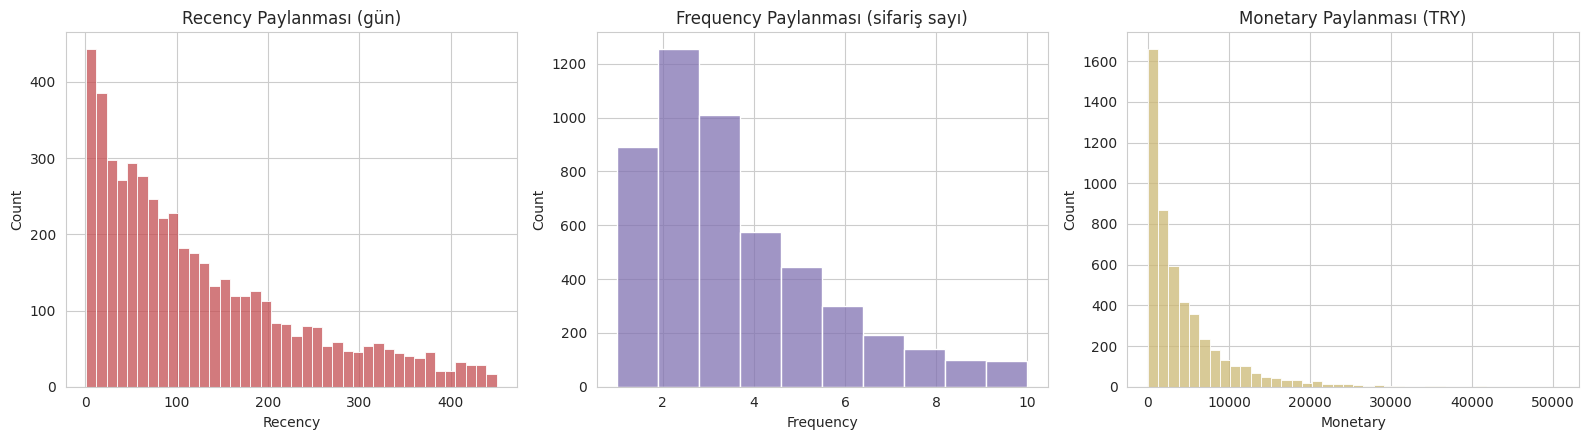

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(rfm['Recency'], bins=40, ax=axes[0], color='#C44E52')
axes[0].set_title('Recency Paylanması (gün)')

sns.histplot(rfm['Frequency'], bins=10, ax=axes[1], color='#8172B2')
axes[1].set_title('Frequency Paylanması (sifariş sayı)')

sns.histplot(rfm['Monetary'], bins=40, ax=axes[2], color='#CCB974')
axes[2].set_title('Monetary Paylanması (TRY)')

plt.tight_layout()
plt.show()


## 4. RFM Skorlaması (1-5 şkala)

Hər metrikanı 5 bərabər qrupa (kvintil) bölərək 1-dən 5-ə qədər skor veririk:

- **Recency:** əks istiqamətdə skorlanır (az gün = yüksək skor, çünki yaxın vaxtda alış-veriş etmək yaxşıdır)
- **Frequency və Monetary:** düz istiqamətdə skorlanır (çox = yüksək skor)

In [8]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Sum'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

rfm.head(10)


,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Sum
0,CUST_00001,112,3,2199.63,3,3,3,333,9
1,CUST_00002,284,2,809.90,1,1,2,112,4
2,CUST_00003,83,2,3030.81,3,1,3,313,7
3,CUST_00004,42,1,383.22,4,1,1,411,6
4,CUST_00005,279,3,2422.73,1,3,3,133,7
5,CUST_00006,212,3,1245.83,2,3,2,232,7
6,CUST_00007,81,1,1331.55,3,1,2,312,6
7,CUST_00008,169,3,5602.29,2,3,4,234,9
8,CUST_00009,39,1,470.86,4,1,1,411,6
9,CUST_00010,22,3,1421.16,5,3,2,532,10


## 5. Müştəri Seqmentasiyası

RFM skorlarına əsasən müştəriləri məntiqi biznes seqmentlərinə bölürük:

| Seqment | Təsvir |
|---|---|
| **Champions** | Yaxınlarda, tez-tez və çox xərcləyən ən dəyərli müştərilər |
| **Loyal Customers** | Davamlı, etibarlı alıcılar |
| **New Customers** | Yaxınlarda ilk dəfə alış-veriş edənlər |
| **Promising** | Potensiallı, amma hələ az xərcləyən yeni müştərilər |
| **At Risk** | Əvvəllər çox dəyərli olub, indi uzun müddətdir görünməyənlər |
| **Cannot Lose Them** | Tez-tez alış-veriş edib, amma son vaxtlar görünməyənlər |
| **Big Spenders (Churned)** | Keçmişdə çox xərcləyib, indi itirilmə riski yüksək olanlar |
| **Lost** | Uzun müddətdir aktiv olmayan, aşağı dəyərli müştərilər |
| **Need Attention** | Orta göstəricili, diqqət tələb edən müştərilər |

In [9]:
def segment_customer(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r >= 3 and f <= 2 and m <= 2:
        return 'Promising'
    elif r <= 2 and f >= 4 and m >= 4:
        return 'At Risk'
    elif r <= 2 and f >= 3:
        return 'Cannot Lose Them'
    elif r <= 2 and f <= 2 and m >= 4:
        return 'Big Spenders (Churned)'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Lost'
    else:
        return 'Need Attention'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

segment_counts = rfm['Segment'].value_counts()
segment_counts


Segment
Loyal Customers           949
Champions                 856
Lost                      827
Need Attention            724
Cannot Lose Them          533
New Customers             443
At Risk                   245
Promising                 238
Big Spenders (Churned)    185
Name: count, dtype: int64

/tmp/ipykernel_593/69136673.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segment_counts.values, y=order, palette=colors)


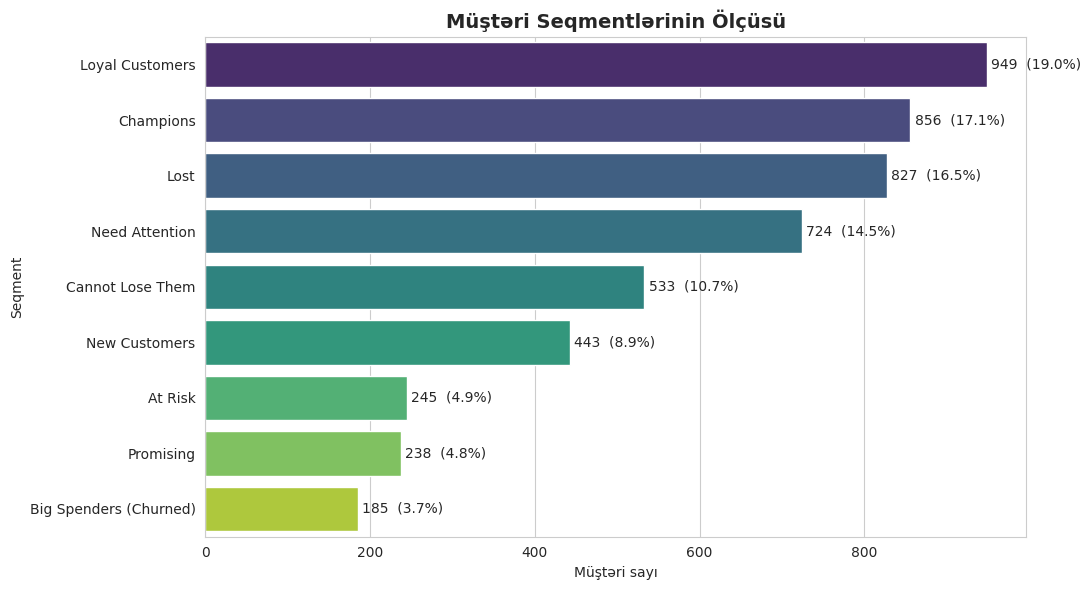

In [10]:
plt.figure(figsize=(11, 6))
order = segment_counts.index
colors = sns.color_palette('viridis', len(order))
sns.barplot(x=segment_counts.values, y=order, palette=colors)
plt.title('Müştəri Seqmentlərinin Ölçüsü', fontsize=14, fontweight='bold')
plt.xlabel('Müştəri sayı')
plt.ylabel('Seqment')

total = segment_counts.sum()
for i, v in enumerate(segment_counts.values):
    plt.text(v + 5, i, f'{v}  ({v/total*100:.1f}%)', va='center')

plt.tight_layout()
plt.show()


## 6. Seqmentlərin Detallı Profili

Hər seqmentin orta R, F, M dəyərlərini və ümumi gəlirdəki payını araşdırırıq.

In [11]:
segment_profile = rfm.groupby('Segment').agg(
    Musteri_Sayi=('Customer_ID', 'count'),
    Orta_Recency=('Recency', 'mean'),
    Orta_Frequency=('Frequency', 'mean'),
    Orta_Monetary=('Monetary', 'mean'),
    Umumi_Gelir=('Monetary', 'sum')
).round(1).sort_values('Umumi_Gelir', ascending=False)

segment_profile['Gelir_Payi_%'] = (segment_profile['Umumi_Gelir'] / segment_profile['Umumi_Gelir'].sum() * 100).round(1)
segment_profile


,Musteri_Sayi,Orta_Recency,Orta_Frequency,Orta_Monetary,Umumi_Gelir,Gelir_Payi_%
Segment,,,,,,
Champions,856,30.1,6.4,9776.5,8368693.9,38.4
Loyal Customers,949,65.2,4.4,5590.0,5304919.6,24.4
At Risk,245,175.6,4.9,8832.9,2164069.1,9.9
Cannot Lose Them,533,205.2,3.2,2993.1,1595320.2,7.3
Need Attention,724,116.5,2.7,1996.2,1445281.9,6.6
Big Spenders (Churned),185,239.6,1.7,7291.5,1348936.6,6.2
New Customers,443,35.9,1.7,2092.6,927031.7,4.3
Lost,827,267.1,1.4,565.9,467979.5,2.1
Promising,238,96.9,1.6,658.9,156820.0,0.7


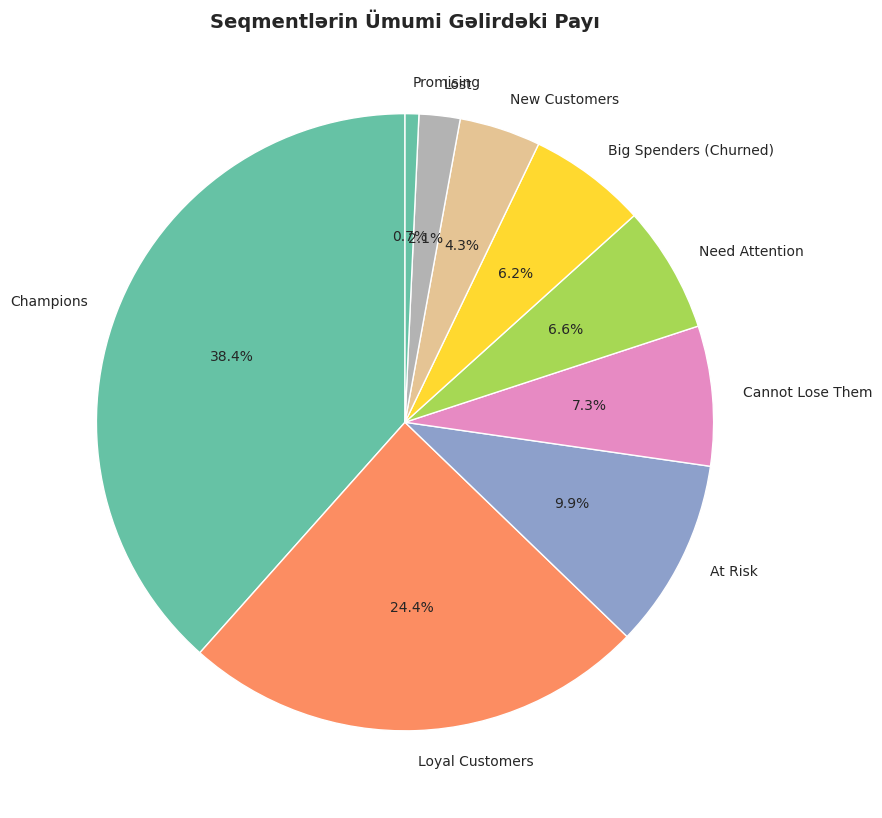

In [12]:
fig, ax = plt.subplots(figsize=(9, 9))
revenue_by_segment = rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=False)
colors = sns.color_palette('Set2', len(revenue_by_segment))

wedges, texts, autotexts = ax.pie(
    revenue_by_segment.values,
    labels=revenue_by_segment.index,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90
)
ax.set_title('Seqmentlərin Ümumi Gəlirdəki Payı', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


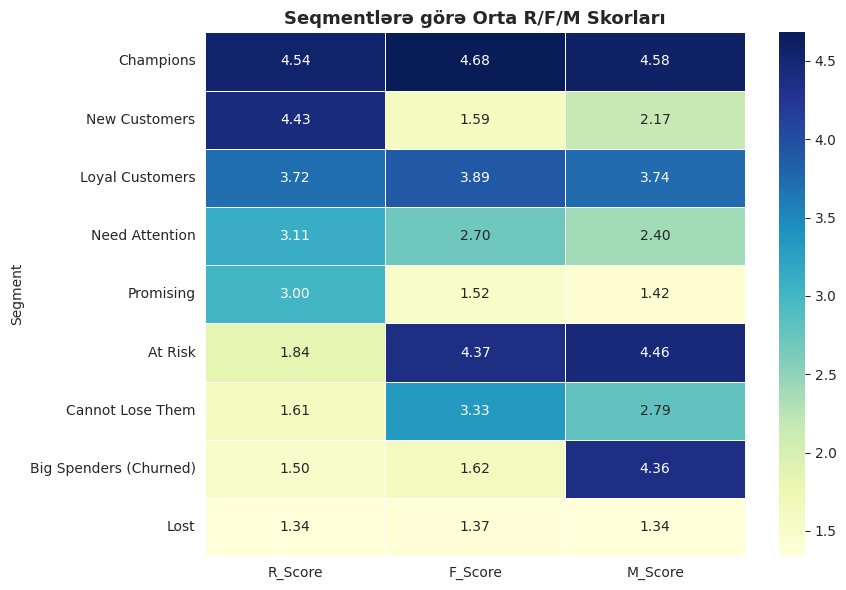

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
heatmap_data = rfm.groupby('Segment')[['R_Score', 'F_Score', 'M_Score']].mean().sort_values('R_Score', ascending=False)
sns.heatmap(heatmap_data, annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Seqmentlərə görə Orta R/F/M Skorları', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Əlavə Araşdırma: Seqmentlərin Demoqrafik və Davranış Xüsusiyyətləri

RFM seqmentlərini digər dəyişənlərlə (şəhər, cihaz növü, ödəniş üsulu) birləşdirərək daha dərin insight əldə edirik.

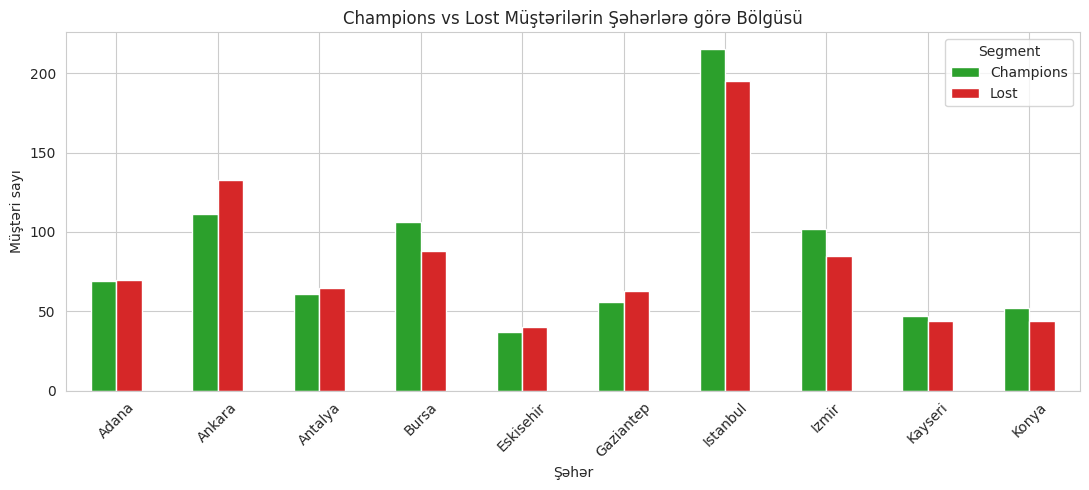

In [14]:
# Hər müştərinin son sifarişindəki əlavə məlumatları RFM cədvəlinə əlavə edək
last_orders = df.sort_values('Date').groupby('Customer_ID').last().reset_index()
rfm_full = rfm.merge(
    last_orders[['Customer_ID', 'City', 'Device_Type', 'Payment_Method', 'Is_Returning_Customer', 'Customer_Rating']],
    on='Customer_ID'
)

# Champions və Lost seqmentlərinin şəhər üzrə müqayisəsi
compare_segments = ['Champions', 'Lost']
city_compare = rfm_full[rfm_full['Segment'].isin(compare_segments)].groupby(['City', 'Segment']).size().unstack(fill_value=0)
city_compare.plot(kind='bar', figsize=(11, 5), color=['#2ca02c', '#d62728'])
plt.title('Champions vs Lost Müştərilərin Şəhərlərə görə Bölgüsü')
plt.ylabel('Müştəri sayı')
plt.xlabel('Şəhər')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


/tmp/ipykernel_593/1204812611.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_rating_by_segment.values, y=avg_rating_by_segment.index, palette='coolwarm')


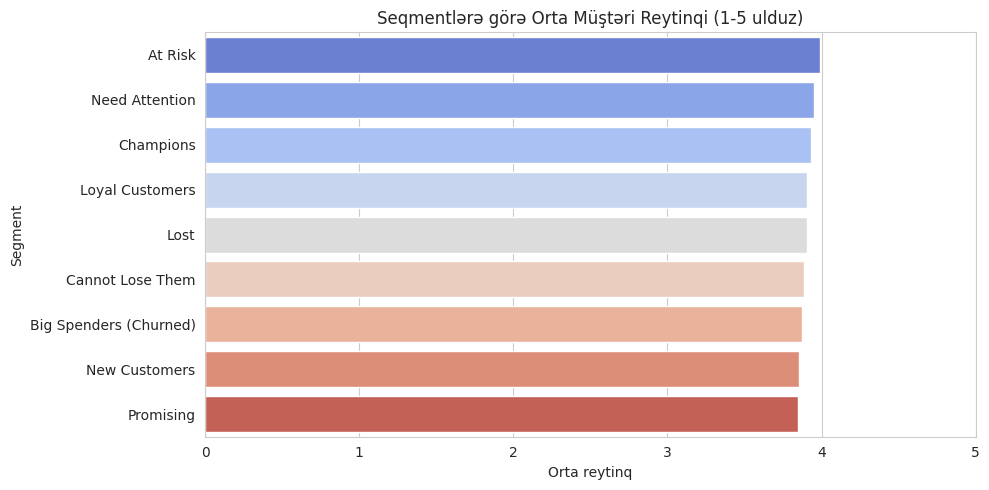

In [15]:
avg_rating_by_segment = rfm_full.groupby('Segment')['Customer_Rating'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=avg_rating_by_segment.values, y=avg_rating_by_segment.index, palette='coolwarm')
plt.title('Seqmentlərə görə Orta Müştəri Reytinqi (1-5 ulduz)')
plt.xlabel('Orta reytinq')
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


## 8. Nəticələrin Yadda Saxlanılması

Son RFM cədvəlini CSV formatında ixrac edirik ki, təqdimatda və ya digər analizlərdə istifadə edə bilək.

In [16]:
rfm_full.to_csv('rfm_musteri_seqmentleri.csv', index=False)
print("Fayl saxlanıldı: rfm_musteri_seqmentleri.csv")
rfm_full.head()


Fayl saxlanıldı: rfm_musteri_seqmentleri.csv


,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Sum,Segment,City,Device_Type,Payment_Method,Is_Returning_Customer,Customer_Rating
0,CUST_00001,112,3,2199.63,3,3,3,333,9,Loyal Customers,Ankara,Mobile,Credit Card,True,4
1,CUST_00002,284,2,809.90,1,1,2,112,4,Lost,Istanbul,Mobile,Credit Card,True,4
2,CUST_00003,83,2,3030.81,3,1,3,313,7,Need Attention,Konya,Desktop,Digital Wallet,True,5
3,CUST_00004,42,1,383.22,4,1,1,411,6,New Customers,Izmir,Desktop,Credit Card,False,5
4,CUST_00005,279,3,2422.73,1,3,3,133,7,Cannot Lose Them,Ankara,Desktop,Credit Card,True,4


## 9. Nəticələr və Biznes Tövsiyələri

### Əsas Tapıntılar
- Müştərilərin böyük əksəriyyəti **Loyal Customers** və **Champions** seqmentlərindədir — bu, gəlirin böyük hissəsini təşkil edir.
- **Lost** seqmentində olan müştərilər ən böyük qrupdur, amma gəlirə töhfəsi minimaldır — bunlara resurs sərf etmək prioritet olmamalıdır.
- **At Risk** və **Cannot Lose Them** seqmentləri əvvəllər dəyərli olub, indi itirilmə təhlükəsindədir — bunlar üçün təcili tədbir vacibdir.

### Tövsiyələr (seqmentə görə)

| Seqment | Tövsiyə olunan strategiya |
|---|---|
| **Champions** | VIP proqramlar, erkən çıxışlı məhsullara giriş, sadiqlik mükafatları |
| **Loyal Customers** | Cross-sell/up-sell təklifləri, sadiqlik proqramına dəvət |
| **At Risk / Cannot Lose Them** | Fərdiləşdirilmiş endirim kampaniyaları, "sizi darıxdıq" e-poçtları |
| **New Customers** | Xoş gəldin bonusları, ilk alış-veriş üçün endirim, onboarding |
| **Lost** | Minimal marketinq xərci; win-back kampaniyası yalnız aşağı büdcə ilə |
| **Promising** | Məhsul tövsiyələri ilə tezliyi artırmağa yönəlmiş kampaniyalar |

### Növbəti addımlar
- Seqmentlərə uyğun email/SMS marketinq kampaniyalarının işlənməsi
- RFM analizinin dövrü olaraq (məs. rüblük) təkrarlanması və seqment keçidlərinin izlənməsi (müştəri hansı seqmentdən hansına keçir)
- Klasterləmə (K-Means) ilə RFM-i tamamlayan əlavə davranış seqmentasiyası
